# vEPAC Multitask GP Surrogate Model - Step 1: Model Training

This notebook implements an end-to-end **Multitask Gaussian Process (`MultitaskExactGP`)** using GPyTorch to predict the **4 Tier 1 & Tier 2 scalars** from 5 laser and target control parameters.

---

### **Input Parameters (5 Laser & Gas Controls)**:
1. `l_energy_J__req_sim`: Laser pulse energy ($J$)
2. `l_focus_z_mm__req_sim`: Laser focal position $z_{foc}$ ($mm$)
3. `l_gdd_fs2__req_sim`: Laser chirp / group delay dispersion ($fs^2$)
4. `g_density__req_sim`: Plasma gas density ($10^{18}\text{ cm}^{-3}$)
5. `g_plateau_mm__req_sim`: Gas target plateau length ($mm$)

### **Target Outputs (4 Tier 1 & Tier 2 Scalars)**:
1. `e_charge_fC`: Electron bunch charge ($fC$) — *Tier 1*
2. `x_yield_ph`: Total betatron X-ray photon yield — *Tier 1*
3. `e_energy_mean_MeV`: Mean electron beam energy ($MeV$) — *Tier 2*
4. `x_energy_mean_keV`: Mean betatron X-ray photon energy ($keV$) — *Tier 2*

---

### **Evaluation & Diagnostics**:
- **Metrics**: Mean Absolute Error (**MAE**), Root Mean Squared Error (**RMSE**), and **$R^2$ Score** in original physical units.
- **Visualizations**: All plots are automatically saved to `notebooks/results/multitask_gp/`:
  - `training_loss.png`
  - `parity_plots.png`
  - `metrics_and_residuals.png`


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import gpytorch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score, mean_squared_error

# Set seeds for exact reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

# Define output directory for saving result plots
# Handles both running from project root or inside notebooks/ directory
RESULTS_DIR = os.path.abspath("results")

os.makedirs(RESULTS_DIR, exist_ok=True)
print(f"Results plots directory: {RESULTS_DIR}")
print(f"PyTorch version: {torch.__version__}")
print(f"GPyTorch version: {gpytorch.__version__}")


def regression_interval_ece(target, mean, std, confidence_levels=None, eps=1e-8):
    target = np.asarray(target, dtype=np.float64)
    mean = np.asarray(mean, dtype=np.float64)
    std = np.clip(np.asarray(std, dtype=np.float64), eps, None)
    if confidence_levels is None:
        confidence_levels = np.linspace(0.05, 0.95, 19)
    confidence_levels = np.asarray(confidence_levels, dtype=np.float64)
    levels_t = torch.as_tensor(confidence_levels, dtype=torch.float64)
    normal = torch.distributions.Normal(
        torch.tensor(0.0, dtype=torch.float64),
        torch.tensor(1.0, dtype=torch.float64),
    )
    z_values = normal.icdf((1.0 + levels_t) / 2.0).cpu().numpy()
    abs_error = np.abs(target - mean)
    empirical_coverage = np.array([
        np.mean(abs_error <= z * std) for z in z_values
    ])
    return float(np.mean(np.abs(empirical_coverage - confidence_levels)))


/opt/anaconda3/envs/bo/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Results plots directory: /Users/tamilarasan.sabapathy/Desktop/Projects/vEPAC/notebooks/vepac_multitaskgp/results
PyTorch version: 2.10.0
GPyTorch version: 1.15.1


## 1. Data Ingestion & Filtering

We load the `merged_all.csv` dataset and filter for rows with valid, non-zero entries for all 4 target scalars (yielding 1,318 valid simulation runs as noted by Xingchi).


In [2]:
# Path to the dataset
data_paths = ["data/merged_all.csv", "./data/merged_all.csv", "../../data/merged_all.csv", "../data/merged_all.csv"]
data_path = next((p for p in data_paths if os.path.exists(p)), None)

if data_path is None:
    raise FileNotFoundError("Could not find merged_all.csv")

df = pd.read_csv(data_path)

# 5 Input control features
input_cols = [
    'l_energy_J__req_sim',    # Laser pulse energy (J)
    'l_focus_z_mm__req_sim',  # Laser focal position zfoc (mm)
    'l_gdd_fs2__req_sim',     # Laser chirp (fs^2)
    'g_density__req_sim',     # Plasma density (10^18 cm^-3)
    'g_plateau_mm__req_sim'   # Gas target plateau length (mm)
]

# 4 Target output scalars (Tier 1 & Tier 2)
target_cols = [
    'e_charge_fC',            # Electron charge (fC)
    'x_yield_ph',             # X-ray photon yield
    'e_energy_mean_MeV',      # Mean electron energy (MeV)
    'x_energy_mean_keV'       # Mean X-ray energy (keV)
]

# User-friendly names with physical units
target_names = {
    'e_charge_fC': 'Electron Charge (fC)',
    'x_yield_ph': 'X-Ray Photon Yield (ph)',
    'e_energy_mean_MeV': 'Mean Electron Energy (MeV)',
    'x_energy_mean_keV': 'Mean X-Ray Energy (keV)'
}

# Filter rows where all 4 targets are non-null and greater than 0
valid_mask = df[target_cols].notna().all(axis=1) & (df['e_charge_fC'] > 0) & (df['x_yield_ph'] > 0)
df_clean = df[valid_mask].reset_index(drop=True)

print(f"Total raw simulation runs: {len(df)}")
print(f"Cleaned simulation runs with valid beam/radiation: {len(df_clean)}")
df_clean[input_cols + target_cols].head()


Total raw simulation runs: 1900
Cleaned simulation runs with valid beam/radiation: 1318


,l_energy_J__req_sim,l_focus_z_mm__req_sim,l_gdd_fs2__req_sim,g_density__req_sim,g_plateau_mm__req_sim,e_charge_fC,x_yield_ph,e_energy_mean_MeV,x_energy_mean_keV
0,0.402345,0.924940,-460.128220,6.272613,1.008692,76748.564130,1.033160e+09,59.133784,1.014766
1,0.483052,1.975375,481.504188,4.264037,1.533474,13060.799150,1.230107e+09,35.745135,0.245130
2,0.344059,0.218910,-161.441721,5.493800,2.227877,156252.460500,3.307685e+09,72.168562,1.666525
3,0.297982,1.523882,-632.415166,4.632340,2.369319,1180.588342,6.157798e+08,68.152328,0.251920
4,0.454278,0.279872,312.673566,3.609853,1.923037,40242.183810,1.716602e+09,100.942967,1.209509


## 2. Train / Test Split & Feature Standardization

We split the 1,318 runs into an **80% training set** (1,054 runs) and a **20% testing set** (264 runs). We standardize inputs and targets to zero mean and unit variance using `StandardScaler`.


In [3]:
X = df_clean[input_cols].values
y = df_clean[target_cols].values

# 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Standardize inputs and targets
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_x.fit_transform(X_train)
X_test_scaled = scaler_x.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

# Convert to PyTorch tensors
train_x = torch.tensor(X_train_scaled, dtype=torch.float32)
train_y = torch.tensor(y_train_scaled, dtype=torch.float32)
test_x = torch.tensor(X_test_scaled, dtype=torch.float32)
test_y = torch.tensor(y_test_scaled, dtype=torch.float32)

print(f"Training samples : {train_x.shape[0]}")
print(f"Testing samples  : {test_x.shape[0]}")


Training samples : 1054
Testing samples  : 264


## 3. Multitask Gaussian Process Architecture

We implement a `MultitaskExactGP` using GPyTorch. The model uses:
- **`MultitaskMean`**: Independent constant prior for each scalar output.
- **`MultitaskKernel`**: Matérn 5/2 base kernel with a rank-2 coregionalization matrix to learn the physical coupling between electron beam properties and X-ray emission.


In [4]:
class MultitaskGPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, likelihood, num_tasks=4):
        super(MultitaskGPModel, self).__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.MultitaskMean(
            gpytorch.means.ConstantMean(), num_tasks=num_tasks
        )
        # Multitask kernel with Matern 5/2 and rank-2 cross-task covariance
        self.covar_module = gpytorch.kernels.MultitaskKernel(
            gpytorch.kernels.ScaleKernel(gpytorch.kernels.MaternKernel(nu=2.5)),
            num_tasks=num_tasks,
            rank=2
        )

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpytorch.distributions.MultitaskMultivariateNormal(mean_x, covar_x)

num_tasks = len(target_cols)
likelihood = gpytorch.likelihoods.MultitaskGaussianLikelihood(num_tasks=num_tasks)
model = MultitaskGPModel(train_x, train_y, likelihood, num_tasks=num_tasks)

print("Multitask GP Model initialized successfully.")


Multitask GP Model initialized successfully.


## 4. Model Training

We train the model hyperparameters using Adam optimizer to minimize the negative Exact Marginal Log Likelihood (MLL).


In [5]:
model.train()
likelihood.train()

optimizer = torch.optim.Adam(model.parameters(), lr=0.05)
mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

num_iterations = 120
loss_history = []

print(f"Training Multitask GP ({num_iterations} iterations)...")
for i in range(num_iterations):
    optimizer.zero_grad()
    output = model(train_x)
    loss = -mll(output, train_y)
    loss.backward()
    optimizer.step()
    
    loss_history.append(loss.item())
    if (i + 1) % 20 == 0 or i == 0:
        print(f"Iter {i+1:03d}/{num_iterations:03d} | Loss (-MLL): {loss.item():.4f}")

print("Training complete.")


Training Multitask GP (120 iterations)...


Iter 001/120 | Loss (-MLL): 1.4531


Iter 020/120 | Loss (-MLL): 0.9712


Iter 040/120 | Loss (-MLL): 0.6503


Iter 060/120 | Loss (-MLL): 0.4235


Iter 080/120 | Loss (-MLL): 0.3281


Iter 100/120 | Loss (-MLL): 0.3025


Iter 120/120 | Loss (-MLL): 0.2953
Training complete.


Saved training loss plot to: /Users/tamilarasan.sabapathy/Desktop/Projects/vEPAC/notebooks/vepac_multitaskgp/results/training_loss.png


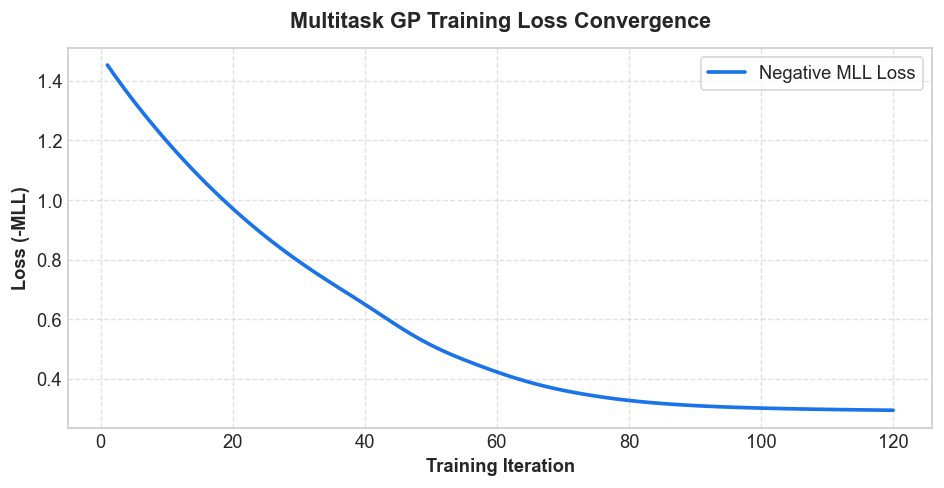

In [6]:
plt.figure(figsize=(8, 4.2), dpi=120)
plt.plot(range(1, num_iterations + 1), loss_history, color='#1a73e8', linewidth=2.2, label='Negative MLL Loss')
plt.title('Multitask GP Training Loss Convergence', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Training Iteration', fontsize=11, fontweight='bold')
plt.ylabel('Loss (-MLL)', fontsize=11, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()

# Save plot to notebooks/results/multitask_gp/
loss_plot_path = os.path.join(RESULTS_DIR, "training_loss.png")
plt.savefig(loss_plot_path, dpi=300, bbox_inches='tight')
print(f"Saved training loss plot to: {loss_plot_path}")

plt.show()


## 5. Save Model Artifacts & Scalers

We save the fitted scalers (`scaler_x.pkl`, `scaler_y.pkl`), trained model weights (`multitask_gp_model.pth`, `multitask_gp_likelihood.pth`), training tensors (`train_x.pt`, `train_y.pt`), test tensors (`test_x.pt`, `test_y.pt`), and feature metadata. These will be loaded by `02_inference.ipynb`.

In [7]:
import joblib

# Directory for model checkpoints
CHECKPOINT_DIR = os.path.abspath(".")

# 1. Save scalers
joblib.dump(scaler_x, os.path.join(CHECKPOINT_DIR, "scaler_x.pkl"))
joblib.dump(scaler_y, os.path.join(CHECKPOINT_DIR, "scaler_y.pkl"))

# 2. Save model and likelihood state dicts
torch.save(model.state_dict(), os.path.join(CHECKPOINT_DIR, "multitask_gp_model.pth"))
torch.save(likelihood.state_dict(), os.path.join(CHECKPOINT_DIR, "multitask_gp_likelihood.pth"))

# 3. Save train/test tensors (ExactGP requires train_x and train_y during initialization for inference)
torch.save(train_x, os.path.join(CHECKPOINT_DIR, "train_x.pt"))
torch.save(train_y, os.path.join(CHECKPOINT_DIR, "train_y.pt"))
torch.save(test_x, os.path.join(CHECKPOINT_DIR, "test_x.pt"))
torch.save(test_y, os.path.join(CHECKPOINT_DIR, "test_y.pt"))

# 4. Save metadata dictionary
metadata = {
    'input_cols': input_cols,
    'target_cols': target_cols,
    'target_names': target_names,
    'num_tasks': num_tasks
}
joblib.dump(metadata, os.path.join(CHECKPOINT_DIR, "model_metadata.pkl"))

print("=" * 65)
print("All training artifacts saved successfully to:", CHECKPOINT_DIR)
print(" - scaler_x.pkl, scaler_y.pkl")
print(" - multitask_gp_model.pth, multitask_gp_likelihood.pth")
print(" - train_x.pt, train_y.pt, test_x.pt, test_y.pt")
print(" - model_metadata.pkl")
print("=" * 65)


All training artifacts saved successfully to: /Users/tamilarasan.sabapathy/Desktop/Projects/vEPAC/notebooks/vepac_multitaskgp
 - scaler_x.pkl, scaler_y.pkl
 - multitask_gp_model.pth, multitask_gp_likelihood.pth
 - train_x.pt, train_y.pt, test_x.pt, test_y.pt
 - model_metadata.pkl
